# Ablate Neural Latent Reconstruction

Minimal visual check for a pretrained autoencoder on Well data.

- reuses `WellDataModule`
- reuses `ZScoreNormalization`
- loads one sample
- shows truth vs reconstruction for one chosen channel

Change `DATASET_NAME` to swap datasets or fields.


In [ ]:
from pathlib import Path
import math
import os
import sys

import fsspec
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from diffusers import AutoencoderKL
from einops import rearrange
from munch import munchify
from the_well.data import WellDataModule
from the_well.data.normalization import ZScoreNormalization
import toml
import yaml

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'


In [2]:
# Setup working directory
repo_root = Path.cwd().resolve()
while not (repo_root / 'pyproject.toml').exists():
    if repo_root.parent == repo_root:
        raise FileNotFoundError('Could not find repo root containing pyproject.toml')
    repo_root = repo_root.parent

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [20]:
# Hyperparameter
DATASET_NAME = 'turbulent_radiative_layer_2D'
CONFIG_PATH = None
SPLIT = 'valid'
FRAME_SOURCE = 'output'
FRAME_INDEX = 0
SAMPLE_INDEX = 0

VAE_MODEL_ID = 'stabilityai/sd-vae-ft-mse'
LOCAL_FILES_ONLY = True

local_base = repo_root / 'data' / 'datasets'
local_stats = local_base / DATASET_NAME / 'stats.yaml'
well_base_path = str(local_base if (local_base / DATASET_NAME).exists() else config.path.well_base_path)
stats_path = str(local_stats if local_stats.exists() else config.path.stats_path)


In [21]:
# Initialize data module
datamodule = WellDataModule(
    well_base_path=well_base_path,
    well_dataset_name=DATASET_NAME,
    batch_size=max(SAMPLE_INDEX + 1, 1),
    use_normalization=False,
    normalization_type=None,
    data_workers=0,
    world_size=1,
    rank=0,
)

if SPLIT == 'train':
    loader = datamodule.train_dataloader()
elif SPLIT == 'valid':
    loader = datamodule.val_dataloader()
elif SPLIT == 'test':
    loader = datamodule.test_dataloader()
else:
    raise ValueError(f'Unsupported split: {SPLIT}')

# Load one data and process
batch = next(iter(loader))

with fsspec.open(stats_path, mode='r') as f:
    stats = yaml.safe_load(f)

normalizer = ZScoreNormalization(
    stats,
    core_field_names=datamodule.train_dataset.core_field_names,
    core_constant_field_names=datamodule.train_dataset.core_constant_field_names,
)

channel_names = []
for order in sorted(datamodule.train_dataset.field_names):
    channel_names.extend(datamodule.train_dataset.field_names[order])

frame_key = 'input_fields' if FRAME_SOURCE == 'input' else 'output_fields'
sample_phys_hwc = batch[frame_key][SAMPLE_INDEX, FRAME_INDEX].to(torch.float32)
sample_z_bchw = rearrange(
    normalizer.normalize_flattened(sample_phys_hwc.unsqueeze(0), mode='variable'),
    'b h w c -> b c h w',
).to(DEVICE)


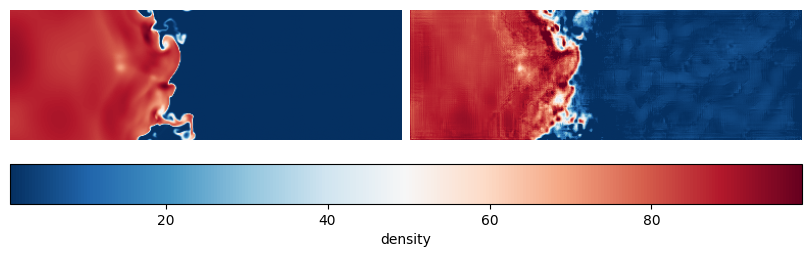

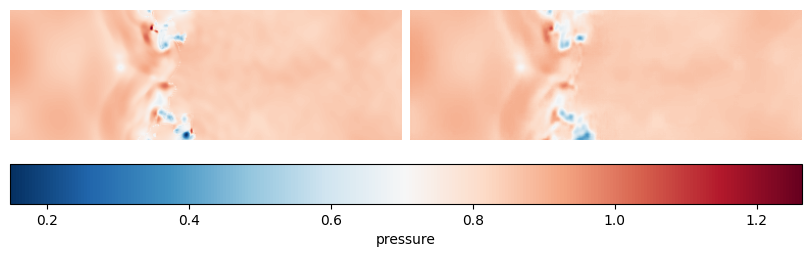

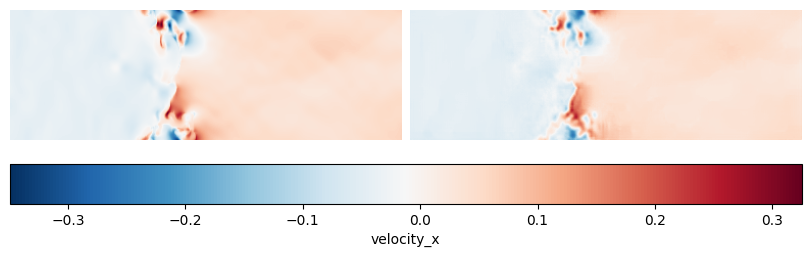

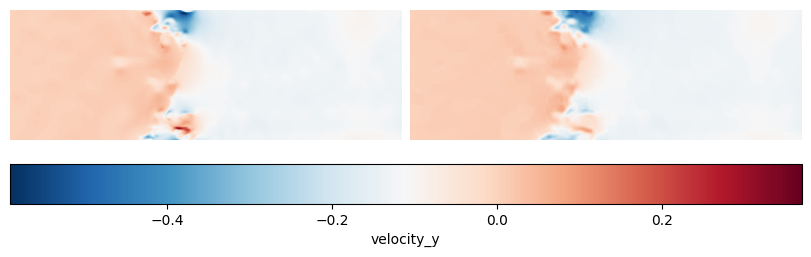

In [23]:
# Inference
vae = AutoencoderKL.from_pretrained(VAE_MODEL_ID).to(DEVICE)
vae.eval()

batch_size, num_channels, height, width = sample_z_bchw.shape

## Stable diffusion pretrained VAE only expects 3-channel RGB, so we have to pad them in multiples of 3 (as batch
n_groups = math.ceil(num_channels / 3)
pad_channels = n_groups * 3 - num_channels
sample_z_padded = F.pad(sample_z_bchw, (0, 0, 0, 0, 0, pad_channels))
packed = rearrange(sample_z_padded, 'b (g rgb) h w -> (b g) rgb h w', rgb=3)

## Also needs to be rescaled to [-1, 1]
scale = packed.abs().amax(dim=(1, 2, 3), keepdim=True).clamp(min=1.0)
packed_for_vae = packed / scale

with torch.no_grad():
    posterior = vae.encode(packed_for_vae).latent_dist
    latents = posterior.mode() * vae.config.scaling_factor
    packed_recon = vae.decode(latents / vae.config.scaling_factor).sample

recon_z_padded = rearrange(packed_recon * scale, '(b g) rgb h w -> b (g rgb) h w', b=batch_size, g=n_groups, rgb=3)
recon_z_bchw = recon_z_padded[:, :num_channels].cpu()
recon_phys_hwc = normalizer.denormalize_flattened(rearrange(recon_z_bchw, 'b c h w -> b h w c'), mode='variable')[0]

# Plot
for channel_idx in range(len(channel_names)):
    
    fig, axes = plt.subplots(1, 2, figsize=(8, 5), constrained_layout=True)
    
    channel_name = channel_names[channel_idx]
    truth_img = sample_phys_hwc[..., channel_idx].cpu()
    recon_img = recon_phys_hwc[..., channel_idx].cpu()
    vmin = truth_img.min().item()
    vmax = truth_img.max().item()
    
    im = axes[0].imshow(truth_img, cmap='RdBu_r', vmin=vmin, vmax=vmax)
    axes[0].axis('off')
    
    axes[1].imshow(recon_img, cmap='RdBu_r', vmin=vmin, vmax=vmax)
    axes[1].axis('off')
    
    cbar = fig.colorbar(im, ax=axes, orientation='horizontal')
    cbar.set_label(channel_name)
    plt.show()


In [25]:
print(f'Original shape: {packed_for_vae.shape}; latent shape: {latents.shape}')

Original shape: torch.Size([2, 3, 128, 384]); latent shape: torch.Size([2, 4, 16, 48])
